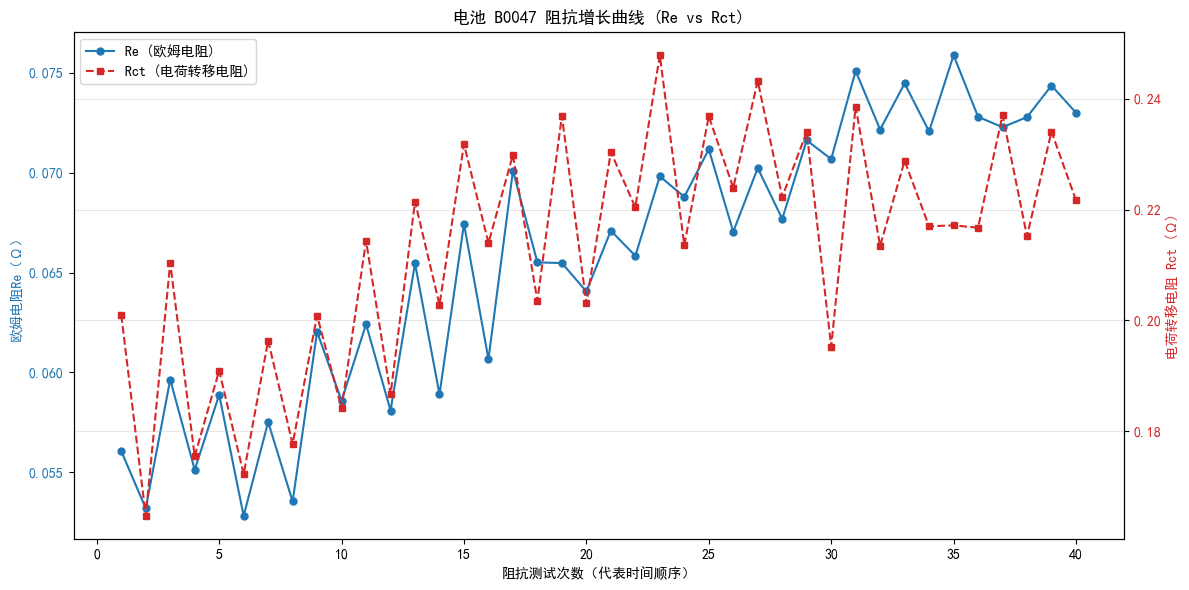

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

meta_df=pd.read_csv('./data/metadata.csv')
imp_df=meta_df[meta_df['type']=='impedance'].copy()

def clean_impedance(val):
    if pd.isna(val):
        return np.nan
    try:
        if isinstance(val,str):
            val=ast.literal_eval(val)
        if isinstance(val,complex):
            return val.real
        return float(val)
    except:
        return np.nan

imp_df['Re_clean']=imp_df['Re'].apply(clean_impedance)
imp_df['Rct_clean']=imp_df['Rct'].apply(clean_impedance)

imp_df=imp_df[(imp_df['Re_clean']>0.01)&(imp_df['Re_clean']<1)]
imp_df=imp_df[(imp_df['Rct_clean']>0.01)&(imp_df['Rct_clean']<1)]

imp_df=imp_df.sort_values(by=['battery_id','uid'])
imp_df['test_seq']=imp_df.groupby('battery_id').cumcount()+1

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

battery_id='B0047'
battery_data=imp_df[imp_df['battery_id']==battery_id]

if len(battery_data)>0:
    fig,ax1=plt.subplots(figsize=(12,6))

    color_re='tab:blue'
    ax1.set_xlabel('阻抗测试次数（代表时间顺序）')
    ax1.set_ylabel('欧姆电阻Re（Ω）',color=color_re)
    ax1.plot(battery_data['test_seq'], battery_data['Re_clean'], color=color_re,
             marker='o', markersize=5, label='Re (欧姆电阻)')
    ax1.tick_params(axis='y', labelcolor=color_re)

    ax2 = ax1.twinx()  # 创建共享X轴的第二个Y轴
    color_rct = 'tab:red'
    ax2.set_ylabel('电荷转移电阻 Rct (Ω)', color=color_rct)
    ax2.plot(battery_data['test_seq'], battery_data['Rct_clean'], 
             color=color_rct, marker='s', markersize=5, linestyle='--', label='Rct (电荷转移电阻)')
    ax2.tick_params(axis='y', labelcolor=color_rct)


    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

    plt.title(f'电池 {battery_id} 阻抗增长曲线 (Re vs Rct)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print(f"未找到电池 {battery_id} 的有效阻抗数据，请检查数据清洗逻辑或更换电池编号。")